In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
empirical_5 = pd.read_csv(
    "outputs/tables/empirical_tail_dependence_5pct.csv"
)

empirical_10 = pd.read_csv(
    "outputs/tables/empirical_tail_dependence_10pct.csv"
)

empirical_5.head()

,Pair,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
0,SPY-TLT,0.109244,0.071429,0.058824,0.071429,0.142857,0.000000
1,SPY-GLD,0.100840,0.107143,0.092437,0.321429,0.092437,0.428571
2,SPY-BTC-USD,0.109244,0.214286,0.109244,0.214286,0.117647,0.535714
3,TLT-GLD,0.092437,0.107143,0.117647,0.178571,0.260504,0.071429
4,TLT-BTC-USD,0.050420,0.071429,0.025210,0.214286,0.000000,0.000000


In [3]:
copula_tail = pd.read_csv(
    "outputs/tables/copula_tail_dependence.csv"
)

copula_tail.head()

,Dataset,Pair,Model,rho,nu,theta,AIC,N,Lambda_L,Lambda_U
0,Long_Normal,GLD-BTC-USD,Gumbel,0.015870,35.906686,1.016794,0.568742,1495,0.000000,0.022767
1,Long_Normal,SPY-BTC-USD,Student-t,0.264761,6.372187,0.300692,-108.129852,1495,0.075180,0.075180
2,Long_Normal,SPY-GLD,Gaussian,-0.005816,50.000000,1.000100,1.950296,1495,0.000000,0.000000
3,Long_Normal,SPY-TLT,Student-t,-0.196397,5.245092,NaN,-78.188873,1495,0.021429,0.021429
4,Long_Normal,TLT-BTC-USD,Gaussian,-0.049516,50.000000,NaN,-1.607713,1495,0.000000,0.000000


In [4]:
print(copula_tail["Dataset"].unique())

['Long_Normal' 'Long_Stress' 'Medium_Normal' 'Medium_Stress'
 'Short_Normal' 'Short_Stress']


In [5]:
copula_lower = copula_tail.pivot(
    index="Pair",
    columns="Dataset",
    values="Lambda_L"
)

In [6]:
column_order = [
    "Short_Normal",
    "Short_Stress",
    "Medium_Normal",
    "Medium_Stress",
    "Long_Normal",
    "Long_Stress"
]

copula_lower = copula_lower[column_order]

copula_lower

Dataset,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
Pair,,,,,,
GLD-BTC-USD,0.000000,0.070790,0.000000,0.000000,0.000000,0.156779
SPY-BTC-USD,0.005204,0.119819,0.001685,0.220620,0.075180,0.428123
SPY-GLD,0.008786,0.104546,0.022307,0.263295,0.000000,0.168540
SPY-TLT,0.017283,0.054336,0.006686,0.060857,0.021429,0.000000
TLT-BTC-USD,0.000000,0.020370,0.000000,0.000000,0.000000,0.000000
TLT-GLD,0.065934,0.204184,0.103194,0.176393,0.101947,0.000000


In [7]:
empirical_lower = empirical_5.set_index("Pair")

empirical_lower = empirical_lower[column_order]

empirical_lower

,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
Pair,,,,,,
SPY-TLT,0.109244,0.071429,0.058824,0.071429,0.142857,0.000000
SPY-GLD,0.100840,0.107143,0.092437,0.321429,0.092437,0.428571
SPY-BTC-USD,0.109244,0.214286,0.109244,0.214286,0.117647,0.535714
TLT-GLD,0.092437,0.107143,0.117647,0.178571,0.260504,0.071429
TLT-BTC-USD,0.050420,0.071429,0.025210,0.214286,0.000000,0.000000
GLD-BTC-USD,0.067227,0.142857,0.126050,0.107143,0.050420,0.428571


In [8]:
print("Empirical pairs:")
print(empirical_lower.index.tolist())

print("\nCopula pairs:")
print(copula_lower.index.tolist())

Empirical pairs:
['SPY-TLT', 'SPY-GLD', 'SPY-BTC-USD', 'TLT-GLD', 'TLT-BTC-USD', 'GLD-BTC-USD']

Copula pairs:
['GLD-BTC-USD', 'SPY-BTC-USD', 'SPY-GLD', 'SPY-TLT', 'TLT-BTC-USD', 'TLT-GLD']


In [9]:
copula_lower = copula_lower.reindex(
    empirical_lower.index
)

In [10]:
tail_difference = (
    copula_lower
    -
    empirical_lower
)

tail_difference

Dataset,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
Pair,,,,,,
SPY-TLT,-0.091960,-0.017092,-0.052138,-0.010572,-0.121428,0.000000
SPY-GLD,-0.092054,-0.002597,-0.070129,-0.058134,-0.092437,-0.260031
SPY-BTC-USD,-0.104039,-0.094467,-0.107558,0.006334,-0.042467,-0.107591
TLT-GLD,-0.026503,0.097041,-0.014453,-0.002178,-0.158557,-0.071429
TLT-BTC-USD,-0.050420,-0.051059,-0.025210,-0.214286,0.000000,0.000000
GLD-BTC-USD,-0.067227,-0.072067,-0.126050,-0.107143,-0.050420,-0.271792


In [11]:
mean_absolute_difference = (
    tail_difference
    .abs()
    .mean()
)

mean_absolute_difference

Dataset
Short_Normal     0.072034
Short_Stress     0.055720
Medium_Normal    0.065923
Medium_Stress    0.066441
Long_Normal      0.077552
Long_Stress      0.118474
dtype: float64

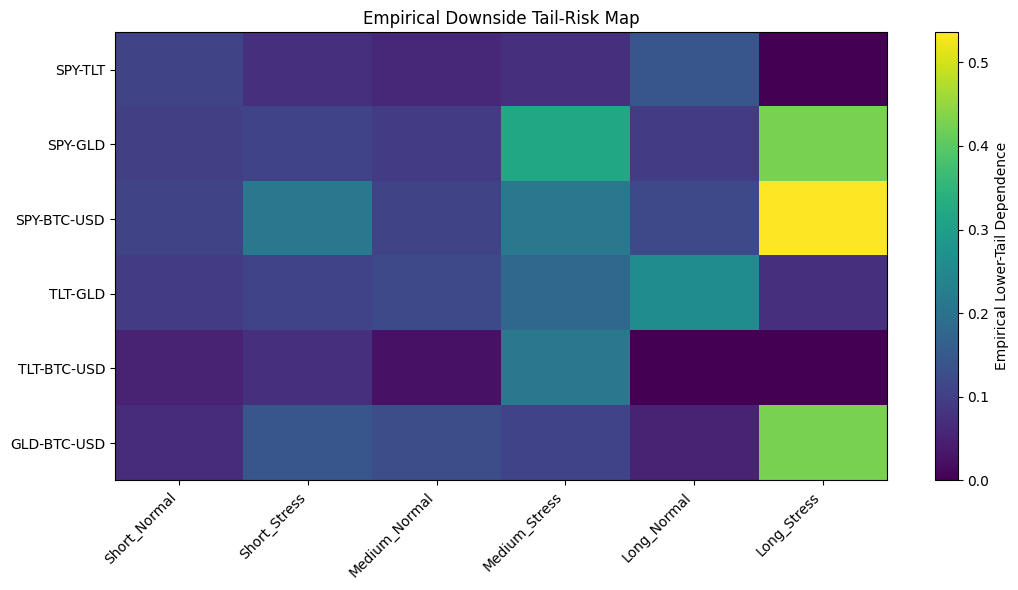

In [12]:
fig, ax = plt.subplots(
    figsize=(11, 6)
)

im = ax.imshow(
    empirical_lower.values,
    aspect="auto"
)

ax.set_xticks(
    range(len(empirical_lower.columns))
)

ax.set_xticklabels(
    empirical_lower.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    range(len(empirical_lower.index))
)

ax.set_yticklabels(
    empirical_lower.index
)

plt.colorbar(
    im,
    ax=ax,
    label="Empirical Lower-Tail Dependence"
)

ax.set_title(
    "Empirical Downside Tail-Risk Map"
)

plt.tight_layout()
plt.show()

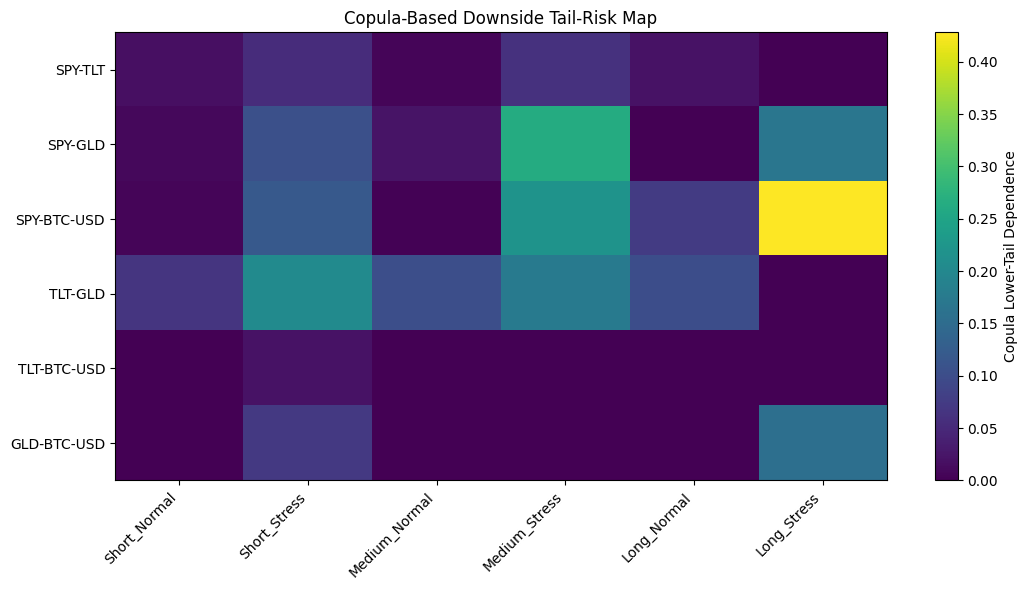

In [13]:
fig, ax = plt.subplots(
    figsize=(11, 6)
)

im = ax.imshow(
    copula_lower.values,
    aspect="auto"
)

ax.set_xticks(
    range(len(copula_lower.columns))
)

ax.set_xticklabels(
    copula_lower.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    range(len(copula_lower.index))
)

ax.set_yticklabels(
    copula_lower.index
)

plt.colorbar(
    im,
    ax=ax,
    label="Copula Lower-Tail Dependence"
)

ax.set_title(
    "Copula-Based Downside Tail-Risk Map"
)

plt.tight_layout()
plt.show()

In [14]:
empirical_stress_change = pd.DataFrame(
    index=empirical_lower.index
)

empirical_stress_change["Short"] = (
    empirical_lower["Short_Stress"]
    -
    empirical_lower["Short_Normal"]
)

empirical_stress_change["Medium"] = (
    empirical_lower["Medium_Stress"]
    -
    empirical_lower["Medium_Normal"]
)

empirical_stress_change["Long"] = (
    empirical_lower["Long_Stress"]
    -
    empirical_lower["Long_Normal"]
)

empirical_stress_change

,Short,Medium,Long
Pair,,,
SPY-TLT,-0.037815,0.012605,-0.142857
SPY-GLD,0.006303,0.228992,0.336134
SPY-BTC-USD,0.105042,0.105042,0.418067
TLT-GLD,0.014706,0.060924,-0.189076
TLT-BTC-USD,0.021008,0.189076,0.000000
GLD-BTC-USD,0.075630,-0.018908,0.378151


In [15]:
copula_stress_change = pd.DataFrame(
    index=copula_lower.index
)

copula_stress_change["Short"] = (
    copula_lower["Short_Stress"]
    -
    copula_lower["Short_Normal"]
)

copula_stress_change["Medium"] = (
    copula_lower["Medium_Stress"]
    -
    copula_lower["Medium_Normal"]
)

copula_stress_change["Long"] = (
    copula_lower["Long_Stress"]
    -
    copula_lower["Long_Normal"]
)

copula_stress_change

,Short,Medium,Long
Pair,,,
SPY-TLT,0.037053,0.054171,-0.021429
SPY-GLD,0.095760,0.240988,0.168540
SPY-BTC-USD,0.114615,0.218935,0.352943
TLT-GLD,0.138250,0.073199,-0.101947
TLT-BTC-USD,0.020370,0.000000,0.000000
GLD-BTC-USD,0.070790,0.000000,0.156779


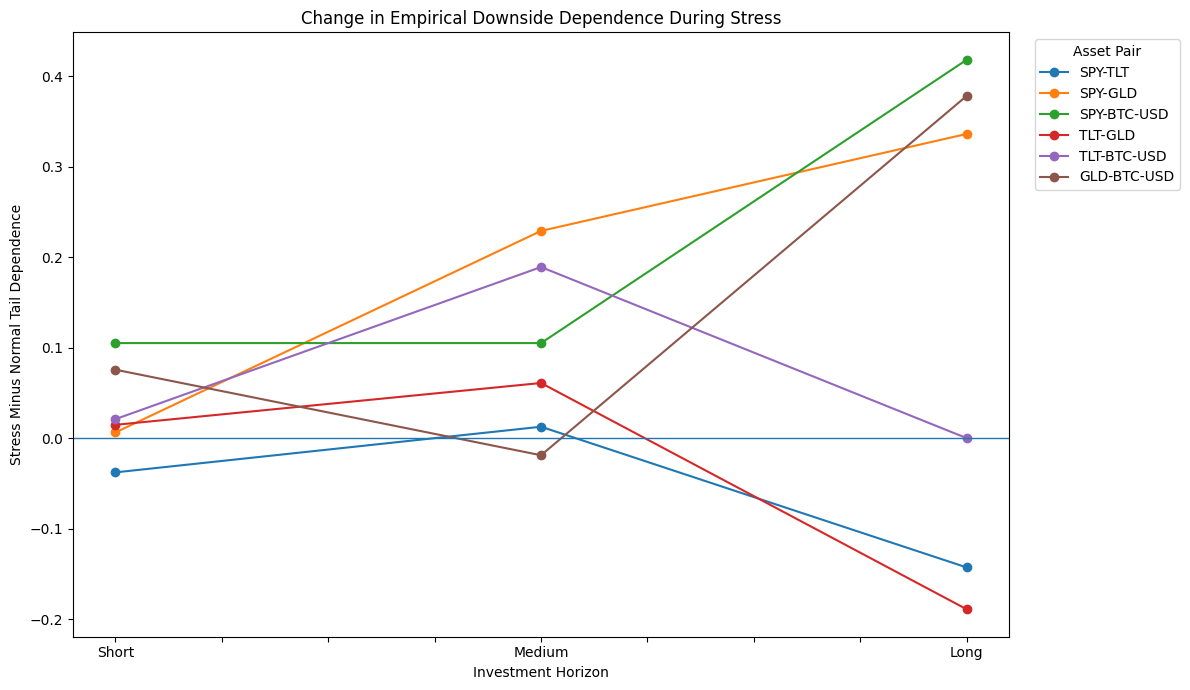

In [16]:
empirical_stress_change.T.plot(
    figsize=(12, 7),
    marker="o"
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Change in Empirical Downside Dependence During Stress"
)

plt.xlabel(
    "Investment Horizon"
)

plt.ylabel(
    "Stress Minus Normal Tail Dependence"
)

plt.legend(
    title="Asset Pair",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

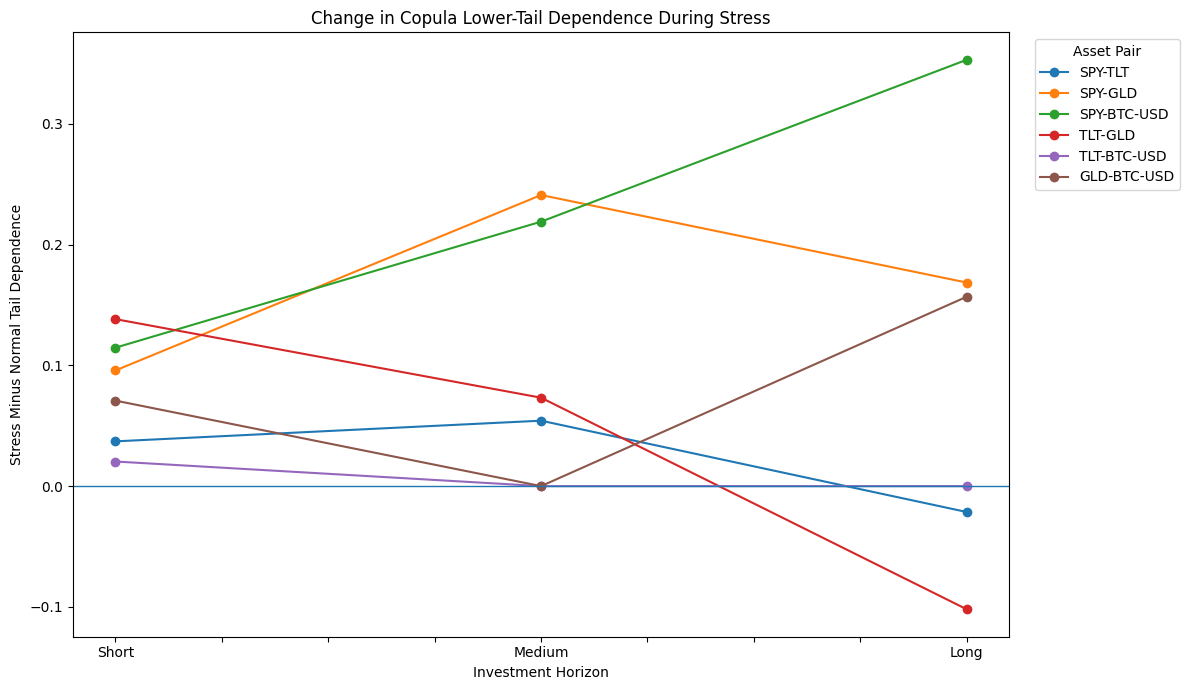

In [17]:
copula_stress_change.T.plot(
    figsize=(12, 7),
    marker="o"
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Change in Copula Lower-Tail Dependence During Stress"
)

plt.xlabel(
    "Investment Horizon"
)

plt.ylabel(
    "Stress Minus Normal Tail Dependence"
)

plt.legend(
    title="Asset Pair",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [18]:
epsilon = 1e-6

In [19]:
dfr = pd.DataFrame(
    index=copula_lower.index
)

dfr["Short"] = (
    copula_lower["Short_Stress"]
    /
    (
        copula_lower["Short_Normal"]
        +
        epsilon
    )
)

dfr["Medium"] = (
    copula_lower["Medium_Stress"]
    /
    (
        copula_lower["Medium_Normal"]
        +
        epsilon
    )
)

dfr["Long"] = (
    copula_lower["Long_Stress"]
    /
    (
        copula_lower["Long_Normal"]
        +
        epsilon
    )
)

dfr

,Short,Medium,Long
Pair,,,
SPY-TLT,3.143665,9.101369,0.000000
SPY-GLD,11.897186,11.802464,168540.465888
SPY-BTC-USD,23.018428,130.824993,5.694583
TLT-GLD,3.096726,1.709313,0.000000
TLT-BTC-USD,20369.742767,0.000000,0.000000
GLD-BTC-USD,70790.417827,0.000000,156779.418141


In [20]:
dfr_safe = dfr.copy()

for pair in dfr_safe.index:

    for horizon in [
        "Short",
        "Medium",
        "Long"
    ]:

        normal_col = f"{horizon}_Normal"

        if copula_lower.loc[
            pair,
            normal_col
        ] < 0.01:

            dfr_safe.loc[
                pair,
                horizon
            ] = np.nan

In [21]:
dfr_safe

,Short,Medium,Long
Pair,,,
SPY-TLT,3.143665,NaN,0.000000
SPY-GLD,NaN,11.802464,NaN
SPY-BTC-USD,NaN,NaN,5.694583
TLT-GLD,3.096726,1.709313,0.000000
TLT-BTC-USD,NaN,NaN,NaN
GLD-BTC-USD,NaN,NaN,NaN


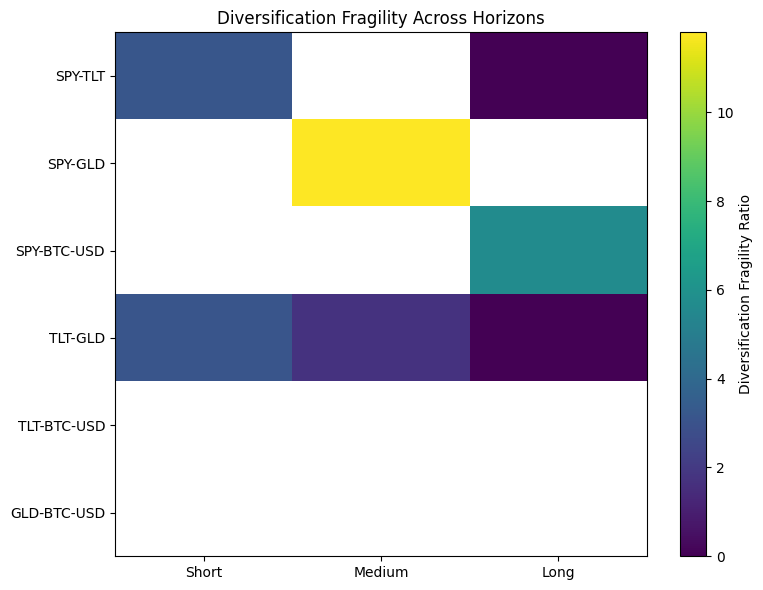

In [22]:
fig, ax = plt.subplots(
    figsize=(8, 6)
)

masked_data = np.ma.masked_invalid(
    dfr_safe.values
)

im = ax.imshow(
    masked_data,
    aspect="auto"
)

ax.set_xticks(
    range(len(dfr_safe.columns))
)

ax.set_xticklabels(
    dfr_safe.columns
)

ax.set_yticks(
    range(len(dfr_safe.index))
)

ax.set_yticklabels(
    dfr_safe.index
)

plt.colorbar(
    im,
    ax=ax,
    label="Diversification Fragility Ratio"
)

ax.set_title(
    "Diversification Fragility Across Horizons"
)

plt.tight_layout()
plt.show()

In [23]:
stress_long = (
    copula_stress_change
    .reset_index()
    .melt(
        id_vars="Pair",
        var_name="Horizon",
        value_name="Stress_Increase"
    )
)

stress_long.head()

,Pair,Horizon,Stress_Increase
0,SPY-TLT,Short,0.037053
1,SPY-GLD,Short,0.095760
2,SPY-BTC-USD,Short,0.114615
3,TLT-GLD,Short,0.138250
4,TLT-BTC-USD,Short,0.020370


In [24]:
stress_long = stress_long.sort_values(
    "Stress_Increase",
    ascending=False
)

stress_long.head(10)

,Pair,Horizon,Stress_Increase
14,SPY-BTC-USD,Long,0.352943
7,SPY-GLD,Medium,0.240988
8,SPY-BTC-USD,Medium,0.218935
13,SPY-GLD,Long,0.168540
17,GLD-BTC-USD,Long,0.156779
3,TLT-GLD,Short,0.138250
2,SPY-BTC-USD,Short,0.114615
1,SPY-GLD,Short,0.095760
9,TLT-GLD,Medium,0.073199
5,GLD-BTC-USD,Short,0.070790


In [25]:
copula_long = (
    copula_lower
    .reset_index()
    .melt(
        id_vars="Pair",
        var_name="Horizon_Regime",
        value_name="Lambda_L"
    )
)

copula_long = copula_long.sort_values(
    "Lambda_L",
    ascending=False
)

copula_long.head(10)

,Pair,Horizon_Regime,Lambda_L
32,SPY-BTC-USD,Long_Stress,0.428123
19,SPY-GLD,Medium_Stress,0.263295
20,SPY-BTC-USD,Medium_Stress,0.220620
9,TLT-GLD,Short_Stress,0.204184
21,TLT-GLD,Medium_Stress,0.176393
31,SPY-GLD,Long_Stress,0.168540
35,GLD-BTC-USD,Long_Stress,0.156779
8,SPY-BTC-USD,Short_Stress,0.119819
7,SPY-GLD,Short_Stress,0.104546
15,TLT-GLD,Medium_Normal,0.103194


In [26]:
copula_long[
    ["Horizon", "Regime"]
] = (
    copula_long[
        "Horizon_Regime"
    ]
    .str.split(
        "_",
        expand=True
    )
)

copula_long.head()

,Pair,Horizon_Regime,Lambda_L,Horizon,Regime
32,SPY-BTC-USD,Long_Stress,0.428123,Long,Stress
19,SPY-GLD,Medium_Stress,0.263295,Medium,Stress
20,SPY-BTC-USD,Medium_Stress,0.220620,Medium,Stress
9,TLT-GLD,Short_Stress,0.204184,Short,Stress
21,TLT-GLD,Medium_Stress,0.176393,Medium,Stress


In [27]:
average_by_horizon = (
    copula_long
    .groupby("Horizon")[
        "Lambda_L"
    ]
    .mean()
)

average_by_horizon

Horizon
Long      0.079333
Medium    0.071253
Short     0.055938
Name: Lambda_L, dtype: float64

In [28]:
average_by_regime = (
    copula_long
    .groupby("Regime")[
        "Lambda_L"
    ]
    .mean()
)

average_by_regime

Regime
Normal    0.023869
Stress    0.113814
Name: Lambda_L, dtype: float64

In [29]:
average_horizon_regime = (
    copula_long
    .groupby(
        [
            "Horizon",
            "Regime"
        ]
    )[
        "Lambda_L"
    ]
    .mean()
    .unstack()
)

average_horizon_regime

Regime,Normal,Stress
Horizon,,
Long,0.033093,0.125574
Medium,0.022312,0.120194
Short,0.016201,0.095674


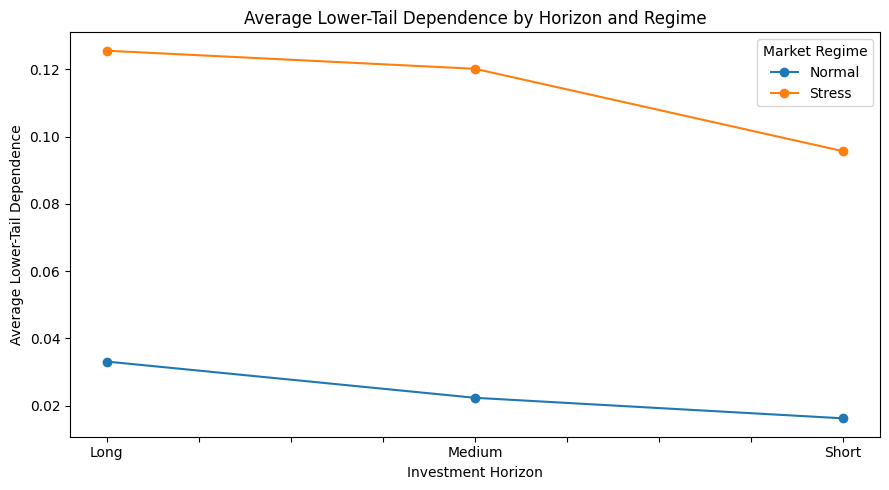

In [30]:
average_horizon_regime.plot(
    figsize=(9, 5),
    marker="o"
)

plt.title(
    "Average Lower-Tail Dependence by Horizon and Regime"
)

plt.xlabel(
    "Investment Horizon"
)

plt.ylabel(
    "Average Lower-Tail Dependence"
)

plt.legend(
    title="Market Regime"
)

plt.tight_layout()
plt.show()

In [31]:
pair_name = "SPY-BTC-USD"

In [32]:
comparison_spy_btc = pd.DataFrame({
    "Empirical": empirical_lower.loc[
        pair_name
    ],
    "Copula": copula_lower.loc[
        pair_name
    ]
})

comparison_spy_btc

,Empirical,Copula
Short_Normal,0.109244,0.005204
Short_Stress,0.214286,0.119819
Medium_Normal,0.109244,0.001685
Medium_Stress,0.214286,0.220620
Long_Normal,0.117647,0.075180
Long_Stress,0.535714,0.428123


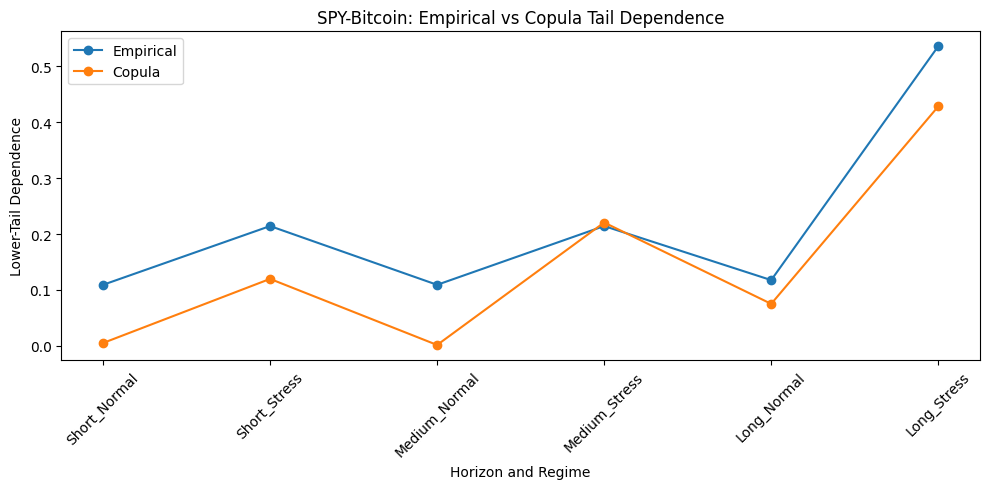

In [33]:
comparison_spy_btc.plot(
    figsize=(10, 5),
    marker="o"
)

plt.title(
    "SPY-Bitcoin: Empirical vs Copula Tail Dependence"
)

plt.xlabel(
    "Horizon and Regime"
)

plt.ylabel(
    "Lower-Tail Dependence"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [34]:
pair_name = "SPY-TLT"

comparison_spy_tlt = pd.DataFrame({
    "Empirical": empirical_lower.loc[
        pair_name
    ],
    "Copula": copula_lower.loc[
        pair_name
    ]
})

comparison_spy_tlt

,Empirical,Copula
Short_Normal,0.109244,0.017283
Short_Stress,0.071429,0.054336
Medium_Normal,0.058824,0.006686
Medium_Stress,0.071429,0.060857
Long_Normal,0.142857,0.021429
Long_Stress,0.000000,0.000000


In [35]:
pair_name = "SPY-GLD"

comparison_spy_gld = pd.DataFrame({
    "Empirical": empirical_lower.loc[
        pair_name
    ],
    "Copula": copula_lower.loc[
        pair_name
    ]
})

comparison_spy_gld

,Empirical,Copula
Short_Normal,0.100840,0.008786
Short_Stress,0.107143,0.104546
Medium_Normal,0.092437,0.022307
Medium_Stress,0.321429,0.263295
Long_Normal,0.092437,0.000000
Long_Stress,0.428571,0.168540


In [36]:
best_models = pd.read_csv(
    "outputs/tables/best_copula_models.csv"
)

best_models.head()

,Dataset,Pair,Model,rho,nu,theta,AIC,N
0,Long_Normal,GLD-BTC-USD,Gumbel,0.015870,35.906686,1.016794,0.568742,1495
1,Long_Normal,SPY-BTC-USD,Student-t,0.264761,6.372187,0.300692,-108.129852,1495
2,Long_Normal,SPY-GLD,Gaussian,-0.005816,50.000000,1.000100,1.950296,1495
3,Long_Normal,SPY-TLT,Student-t,-0.196397,5.245092,NaN,-78.188873,1495
4,Long_Normal,TLT-BTC-USD,Gaussian,-0.049516,50.000000,NaN,-1.607713,1495


In [37]:
model_map = best_models.pivot(
    index="Pair",
    columns="Dataset",
    values="Model"
)

model_map = model_map[
    column_order
]

model_map

Dataset,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
Pair,,,,,,
GLD-BTC-USD,Gaussian,Student-t,Gumbel,Gumbel,Gumbel,Student-t
SPY-BTC-USD,Student-t,Student-t,Clayton,Student-t,Student-t,Clayton
SPY-GLD,Student-t,Student-t,Student-t,Student-t,Gaussian,Student-t
SPY-TLT,Student-t,Student-t,Student-t,Student-t,Student-t,Gaussian
TLT-BTC-USD,Gaussian,Student-t,Gaussian,Gumbel,Gaussian,Gaussian
TLT-GLD,Student-t,Student-t,Student-t,Student-t,Student-t,Gaussian


In [38]:
short_transitions = pd.DataFrame({
    "Normal": model_map["Short_Normal"],
    "Stress": model_map["Short_Stress"]
})

short_transitions

,Normal,Stress
Pair,,
GLD-BTC-USD,Gaussian,Student-t
SPY-BTC-USD,Student-t,Student-t
SPY-GLD,Student-t,Student-t
SPY-TLT,Student-t,Student-t
TLT-BTC-USD,Gaussian,Student-t
TLT-GLD,Student-t,Student-t


In [39]:
medium_transitions = pd.DataFrame({
    "Normal": model_map["Medium_Normal"],
    "Stress": model_map["Medium_Stress"]
})

medium_transitions

,Normal,Stress
Pair,,
GLD-BTC-USD,Gumbel,Gumbel
SPY-BTC-USD,Clayton,Student-t
SPY-GLD,Student-t,Student-t
SPY-TLT,Student-t,Student-t
TLT-BTC-USD,Gaussian,Gumbel
TLT-GLD,Student-t,Student-t


In [40]:
long_transitions = pd.DataFrame({
    "Normal": model_map["Long_Normal"],
    "Stress": model_map["Long_Stress"]
})

long_transitions

,Normal,Stress
Pair,,
GLD-BTC-USD,Gumbel,Student-t
SPY-BTC-USD,Student-t,Clayton
SPY-GLD,Gaussian,Student-t
SPY-TLT,Student-t,Gaussian
TLT-BTC-USD,Gaussian,Gaussian
TLT-GLD,Student-t,Gaussian


In [41]:
summary_rows = []

for pair in copula_lower.index:

    row = {
        "Pair": pair,
        
        "Short_Normal": copula_lower.loc[
            pair,
            "Short_Normal"
        ],
        
        "Short_Stress": copula_lower.loc[
            pair,
            "Short_Stress"
        ],
        
        "Medium_Normal": copula_lower.loc[
            pair,
            "Medium_Normal"
        ],
        
        "Medium_Stress": copula_lower.loc[
            pair,
            "Medium_Stress"
        ],
        
        "Long_Normal": copula_lower.loc[
            pair,
            "Long_Normal"
        ],
        
        "Long_Stress": copula_lower.loc[
            pair,
            "Long_Stress"
        ],
        
        "Largest_Stress_Change": (
            copula_stress_change
            .loc[pair]
            .max()
        )
    }

    summary_rows.append(row)

research_summary = pd.DataFrame(
    summary_rows
)

research_summary

,Pair,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress,Largest_Stress_Change
0,SPY-TLT,0.017283,0.054336,0.006686,0.060857,0.021429,0.000000,0.054171
1,SPY-GLD,0.008786,0.104546,0.022307,0.263295,0.000000,0.168540,0.240988
2,SPY-BTC-USD,0.005204,0.119819,0.001685,0.220620,0.075180,0.428123,0.352943
3,TLT-GLD,0.065934,0.204184,0.103194,0.176393,0.101947,0.000000,0.138250
4,TLT-BTC-USD,0.000000,0.020370,0.000000,0.000000,0.000000,0.000000,0.020370
5,GLD-BTC-USD,0.000000,0.070790,0.000000,0.000000,0.000000,0.156779,0.156779


In [42]:
empirical_lower.to_csv(
    "outputs/tables/tail_map_empirical.csv"
)

copula_lower.to_csv(
    "outputs/tables/tail_map_copula.csv"
)

tail_difference.to_csv(
    "outputs/tables/empirical_vs_copula_difference.csv"
)

empirical_stress_change.to_csv(
    "outputs/tables/empirical_stress_change.csv"
)

copula_stress_change.to_csv(
    "outputs/tables/copula_stress_change.csv"
)

dfr_safe.to_csv(
    "outputs/tables/diversification_fragility_ratio_final.csv"
)

model_map.to_csv(
    "outputs/tables/copula_model_map.csv"
)

research_summary.to_csv(
    "outputs/tables/tail_risk_summary.csv",
    index=False
)

In [43]:
print(
    "Notebook 07 completed successfully."
)

print(
    "\nAverage lower-tail dependence by horizon/regime:"
)

display(
    average_horizon_regime.round(3)
)

print(
    "\nLargest stress increases:"
)

display(
    stress_long.head(10).round(3)
)

print(
    "\nWinning copula map:"
)

display(
    model_map
)

Notebook 07 completed successfully.

Average lower-tail dependence by horizon/regime:


Regime,Normal,Stress
Horizon,,
Long,0.033,0.126
Medium,0.022,0.120
Short,0.016,0.096



Largest stress increases:


,Pair,Horizon,Stress_Increase
14,SPY-BTC-USD,Long,0.353
7,SPY-GLD,Medium,0.241
8,SPY-BTC-USD,Medium,0.219
13,SPY-GLD,Long,0.169
17,GLD-BTC-USD,Long,0.157
3,TLT-GLD,Short,0.138
2,SPY-BTC-USD,Short,0.115
1,SPY-GLD,Short,0.096
9,TLT-GLD,Medium,0.073
5,GLD-BTC-USD,Short,0.071



Winning copula map:


Dataset,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
Pair,,,,,,
GLD-BTC-USD,Gaussian,Student-t,Gumbel,Gumbel,Gumbel,Student-t
SPY-BTC-USD,Student-t,Student-t,Clayton,Student-t,Student-t,Clayton
SPY-GLD,Student-t,Student-t,Student-t,Student-t,Gaussian,Student-t
SPY-TLT,Student-t,Student-t,Student-t,Student-t,Student-t,Gaussian
TLT-BTC-USD,Gaussian,Student-t,Gaussian,Gumbel,Gaussian,Gaussian
TLT-GLD,Student-t,Student-t,Student-t,Student-t,Student-t,Gaussian
